ATTENZIONE: 12 righe escluse (assenti, NaN, zero o negative):


,massa,mdot,elemento_ionizzato,luminosita_cloudy,luminosita_analitico
1,1.000000e+08,0.001,CIV,0.0,7.389999e+37
8,1.000000e+08,0.050,CIV,0.0,4.600695e+41
15,1.000000e+08,0.100,CIV,0.0,2.480953e+42
22,1.000000e+08,0.500,CIV,0.0,6.270025e+43
29,5.000000e+08,0.001,CIV,0.0,3.762232e+38
36,5.000000e+08,0.050,CIV,0.0,8.652800e+40
43,5.000000e+08,0.100,CIV,0.0,8.615329e+41
50,5.000000e+08,0.500,CIV,0.0,6.202382e+43
57,1.000000e+09,0.001,CIV,0.0,7.622627e+38
64,1.000000e+09,0.050,CIV,0.0,2.437655e+40


Punti validi: 72 su 84 attesi
Combinazioni massa-mdot rappresentate: 12


,massa,mdot,elemento_ionizzato,logL_cloudy,logL_analitico
0,100000000.0,0.001,CIII,30.054994,38.046969
2,100000000.0,0.001,Halpha,36.335243,36.546994
3,100000000.0,0.001,Hbeta,35.901710,36.100051
4,100000000.0,0.001,Hdelta,35.371979,35.518513
5,100000000.0,0.001,HeII,31.386564,37.830983


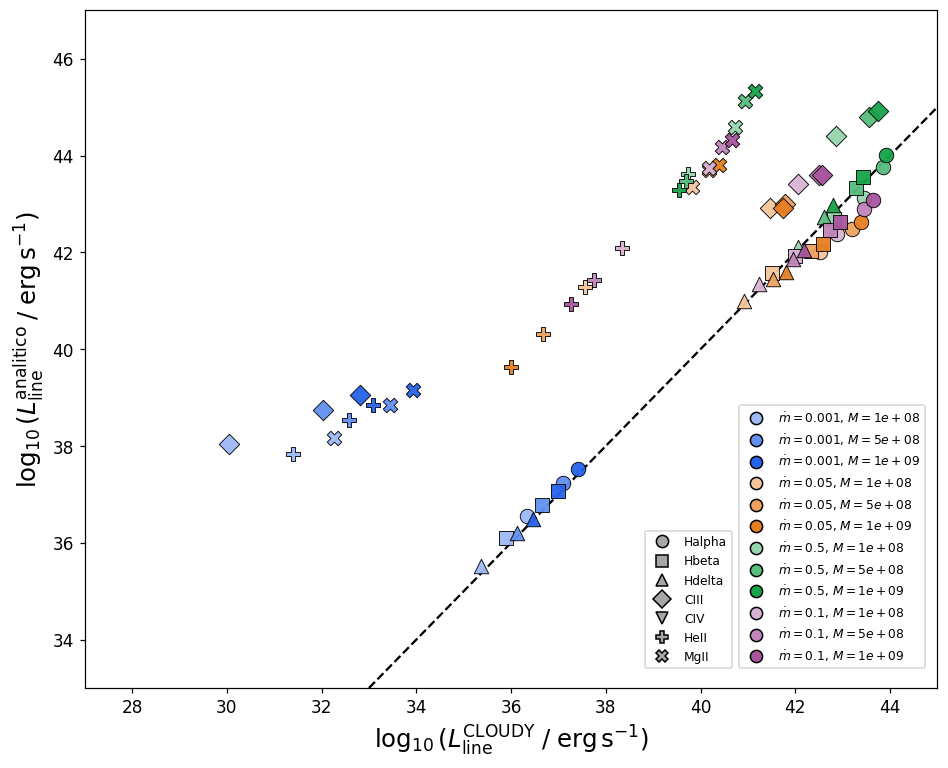

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import to_rgb
from IPython.display import display

# I file TXT devono stare nella stessa cartella del notebook,
# oppure modificare qui i percorsi.
CLOUDY_FILE = Path("luminosita_teoriche_BLR.txt")
ANALYTIC_FILE = Path("luminosita_teoriche_BLR_analitiche.txt")
FIGURE_FILE = Path("confronto_CLOUDY_analitico.png")

LINES = ["Halpha", "Hbeta", "Hdelta", "CIII", "CIV", "HeII", "MgII"]
MARKERS = {"Halpha": "o", "Hbeta": "s", "Hdelta": "^", "CIII": "D",
           "CIV": "v", "HeII": "P", "MgII": "X"}
MASSES = [1e8, 5e8, 1e9]
MDOTS = [1e-3, 5e-2, 5e-1, 1e-1]

# Un colore base per ogni mdot; tre luminosità/tonalità per le masse.
BASE_COLORS = {
    1e-3: "#2563eb",  # blu
    5e-2: "#e67e22",  # arancione
    5e-1: "#16a34a",  # verde
    1e-1: "#a855a0",  # viola
}

plt.rcParams.update({"font.size": 11, "axes.labelsize": 12, "figure.dpi": 110})


def read_results(path, columns, label):
    """Legge un TXT con intestazione commentata (#), separato da spazi/tab."""
    if not path.is_file():
        raise FileNotFoundError(f"File {label} non trovato: {path.resolve()}")
    df = pd.read_csv(path, sep=r"\s+", comment="#", header=None, names=columns)
    if df.empty:
        raise ValueError(f"File {label} vuoto: {path}")
    for col in ("massa", "mdot", "luminosita"):
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df["elemento_ionizzato"] = df["elemento_ionizzato"].astype(str).str.strip()
    if df[["massa", "mdot"]].isna().any().any():
        raise ValueError(f"Masse o mdot non numerici in {label}")
    keys = ["massa", "mdot", "elemento_ionizzato"]
    if df.duplicated(keys).any():
        raise ValueError(f"Righe duplicate in {label}:\n{df.loc[df.duplicated(keys, keep=False), keys]}")
    return df

cloudy_cols = ["massa", "mdot", "elemento_ionizzato", "lambda_trans", "luminosita", "sigma_lum"]
analytic_cols = ["massa", "mdot", "regime", "elemento_ionizzato", "lambda_trans",
                 "luminosita", "sigma_lum", "Q_H", "L_ion", "metodo"]

cloudy = read_results(CLOUDY_FILE, cloudy_cols, "CLOUDY")
analytic = read_results(ANALYTIC_FILE, analytic_cols, "analitico")

# Associazione esatta per (massa, mdot, riga); NON per posizione nel file.
keys = ["massa", "mdot", "elemento_ionizzato"]
comparison = cloudy[keys + ["luminosita"]].merge(
    analytic[keys + ["luminosita"]], on=keys,
    how="outer", suffixes=("_cloudy", "_analitico"), validate="one_to_one", indicator=True
)

if (comparison["_merge"] != "both").any():
    print("ATTENZIONE: alcune combinazioni sono presenti in un solo file:")
    display(comparison.loc[comparison["_merge"] != "both", keys + ["_merge"]])

comparison = comparison.loc[comparison["elemento_ionizzato"].isin(LINES)].copy()
valid = ((comparison["_merge"] == "both") &
         np.isfinite(comparison["luminosita_cloudy"]) &
         np.isfinite(comparison["luminosita_analitico"]) &
         (comparison["luminosita_cloudy"] > 0) &
         (comparison["luminosita_analitico"] > 0))
invalid = comparison.loc[~valid, keys + ["luminosita_cloudy", "luminosita_analitico"]]
if not invalid.empty:
    print(f"ATTENZIONE: {len(invalid)} righe escluse (assenti, NaN, zero o negative):")
    display(invalid)
comparison = comparison.loc[valid].copy()
if comparison.empty:
    raise ValueError("Nessuna coppia di luminosità positiva e valida da rappresentare.")


# Trasformazione: le coordinate del grafico sono GIA' i logaritmi delle luminosità.
comparison["logL_cloudy"] = np.log10(comparison["luminosita_cloudy"])
comparison["logL_analitico"] = np.log10(comparison["luminosita_analitico"])

print(f"Punti validi: {len(comparison)} su {len(MASSES)*len(MDOTS)*len(LINES)} attesi")
print(f"Combinazioni massa-mdot rappresentate: {comparison[['massa', 'mdot']].drop_duplicates().shape[0]}")
display(comparison[["massa", "mdot", "elemento_ionizzato", "logL_cloudy", "logL_analitico"]].head())


def blend_with_white(color, weight):
    """weight=0: bianco; weight=1: colore base."""
    rgb = np.array(to_rgb(color))
    return tuple((1 - weight) * np.ones(3) + weight * rgb)

# Masse crescenti -> toni progressivamente più scuri/saturi.
MASS_WEIGHTS = {1e8: 0.45, 5e8: 0.72, 1e9: 1.0}

fig, ax = plt.subplots(figsize=(10, 8))

# Un colore diverso per ciascuna delle 12 coppie (M, mdot).
for mdot in MDOTS:
    for mass in MASSES:
        selected = comparison.loc[np.isclose(comparison["mdot"], mdot, rtol=1e-9)
                                  & np.isclose(comparison["massa"], mass, rtol=1e-9)]
        color = blend_with_white(BASE_COLORS[mdot], MASS_WEIGHTS[mass])
        for line in LINES:
            rows = selected.loc[selected["elemento_ionizzato"] == line]
            if rows.empty:
                continue
            ax.scatter(
    rows["logL_cloudy"],
    rows["logL_analitico"],
    marker=MARKERS[line],
    s=90,
    c=[color],
    edgecolors="black",
    linewidths=0.6,
    alpha=0.95,
    zorder=3
)

# Gli assi sono LINEARI perché i dati sono già stati trasformati con log10.
# Non usare ax.set_xscale("log") né ax.set_yscale("log")!
ax.set_xlabel(r"$\log_{10}(L_{\rm line}^{\rm CLOUDY}\;/\;\mathrm{erg\,s^{-1}})$", fontsize=16)
ax.set_ylabel(r"$\log_{10}(L_{\rm line}^{\rm analitico}\;/\;\mathrm{erg\,s^{-1}})$",fontsize=16)

# Diagonale infinita y=x nello SPAZIO DEI LOGARITMI.
# Non modifica i limiti automatici degli assi e si adatta a eventuali limiti manuali.
ax.axline((0, 0), slope=1, color="black", linestyle="--",
          linewidth=1.5, zorder=1)


# Nessun limite imposto. Se vorrai, potrai aggiungere per esempio:
ax.set_xlim(27, 45)
ax.set_ylim(33, 47)


# Legenda 1: simboli delle sette righe.
line_handles = [
    Line2D([], [], marker=MARKERS[line], linestyle="None",
           markersize=8, markerfacecolor="0.65",
           markeredgecolor="black", label=line)
    for line in LINES
]

legend_lines = ax.legend(
    handles=line_handles,
    loc="lower left",
    bbox_to_anchor=(0.65, 0.02),
    fontsize=8,
    frameon=True
)
ax.add_artist(legend_lines)


# Legenda 2: combinazioni massa/mdot.
color_handles = []
for mdot in MDOTS:
    for mass in MASSES:
        color_handles.append(
            Line2D([], [], marker="o", linestyle="None",
                   markersize=8,
                   markerfacecolor=blend_with_white(
                       BASE_COLORS[mdot], MASS_WEIGHTS[mass]
                   ),
                   markeredgecolor="black",
                   label=rf"$\dot m={mdot:g}$, $M={mass:.0e}$")
        )

legend_colors = ax.legend(
    handles=color_handles,
    loc="lower left",
    bbox_to_anchor=(0.76, 0.02),
    fontsize=8,
    title_fontsize=10,
    frameon=True
)

#fig.subplots_adjust(right=0.66)
#fig.savefig(FIGURE_FILE, dpi=250, bbox_inches="tight")
plt.show()
#print(f"Grafico salvato in: {FIGURE_FILE.resolve()}")

/tmp/ipykernel_2557/2070284211.py:96: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.05, 1, 0.985])


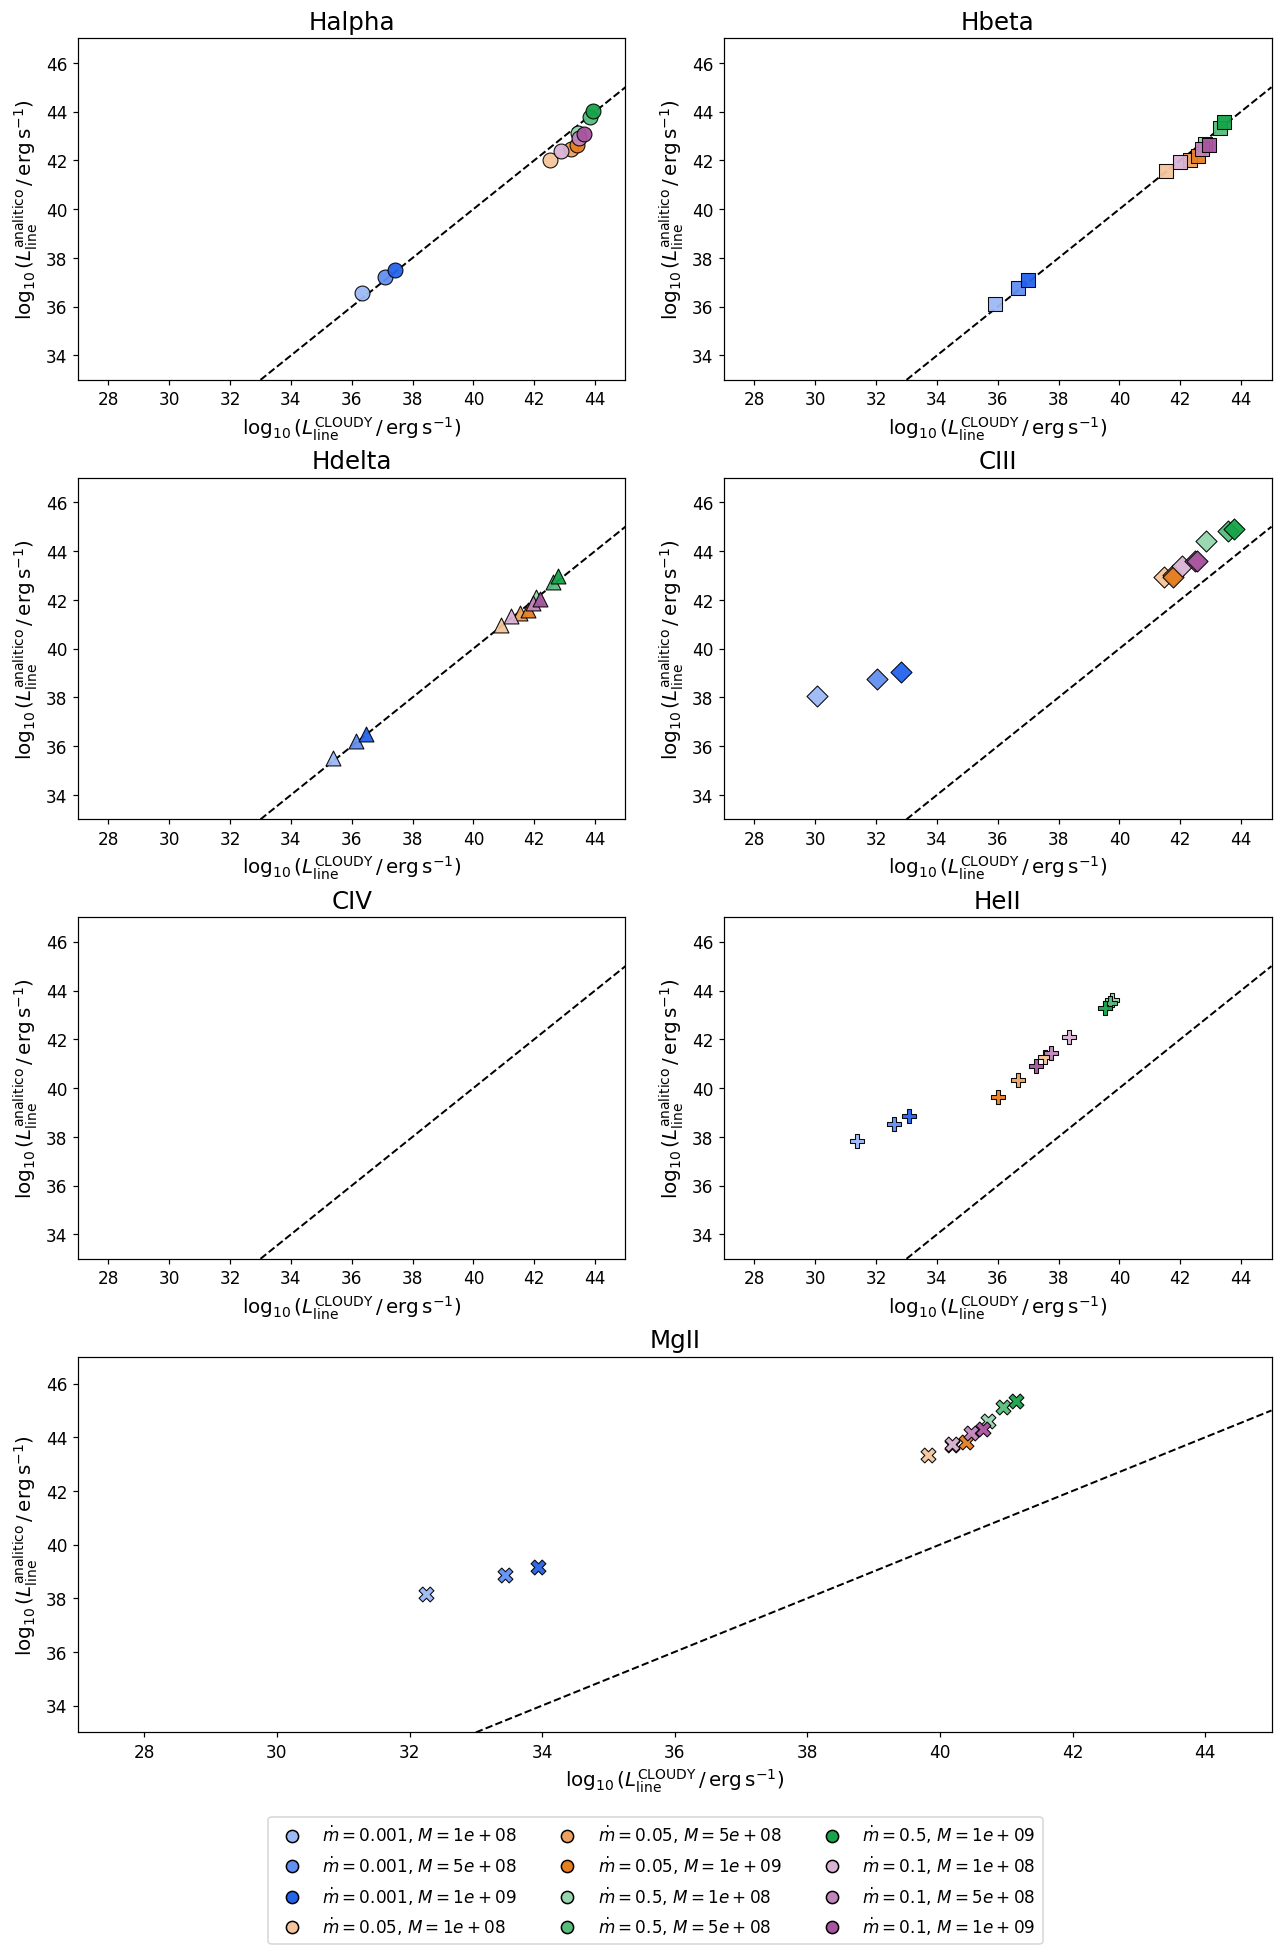

In [3]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ============================================================
# FIGURA CON 7 SOTTOPLOT: 2, 2, 2, 1
# ============================================================

fig = plt.figure(figsize=(14, 20))
gs = fig.add_gridspec(4, 2, height_ratios=[1, 1, 1, 1.1], hspace=0.28, wspace=0.18)

# 6 pannelli normali + ultimo pannello che occupa entrambe le colonne
axes = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1]),
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
    fig.add_subplot(gs[2, 0]),
    fig.add_subplot(gs[2, 1]),
    fig.add_subplot(gs[3, :])   # ultimo pannello su tutta la riga
]

# Se vuoi mantenere limiti uguali in tutti i pannelli:
XMIN, XMAX = 27, 45
YMIN, YMAX = 33, 47

for ax, line in zip(axes, LINES):

    # seleziona solo la riga corrente
    df_line = comparison.loc[comparison["elemento_ionizzato"] == line].copy()

    # disegna i punti per tutte le 12 combinazioni (massa, mdot)
    for mdot in MDOTS:
        for mass in MASSES:
            selected = df_line.loc[
                np.isclose(df_line["mdot"], mdot, rtol=1e-9) &
                np.isclose(df_line["massa"], mass, rtol=1e-9)
            ]

            if selected.empty:
                continue

            color = blend_with_white(BASE_COLORS[mdot], MASS_WEIGHTS[mass])

            ax.scatter(
                selected["logL_cloudy"].to_numpy(),
                selected["logL_analitico"].to_numpy(),
                marker=MARKERS[line],   # un solo simbolo per questo pannello
                s=95,
                c=[color],
                edgecolors="black",
                linewidths=0.7,
                alpha=0.95,
                zorder=3
            )

    # bisettrice y=x
    ax.axline((0, 0), slope=1, color="black", linestyle="--", linewidth=1.3, zorder=1)

    # titoli e assi
    ax.set_title(line, fontsize=16)
    ax.set_xlabel(r"$\log_{10}(L_{\rm line}^{\rm CLOUDY}\,/\,\mathrm{erg\,s^{-1}})$", fontsize=13)
    ax.set_ylabel(r"$\log_{10}(L_{\rm line}^{\rm analitico}\,/\,\mathrm{erg\,s^{-1}})$", fontsize=13)

    # limiti uguali per tutti
    ax.set_xlim(XMIN, XMAX)
    ax.set_ylim(YMIN, YMAX)

    ax.tick_params(labelsize=11)

# ============================================================
# LEGENDA UNICA PER I COLORI (12 combinazioni massa-mdot)
# ============================================================

color_handles = []
for mdot in MDOTS:
    for mass in MASSES:
        color_handles.append(
            Line2D(
                [], [], marker="o", linestyle="None",
                markersize=8,
                markerfacecolor=blend_with_white(BASE_COLORS[mdot], MASS_WEIGHTS[mass]),
                markeredgecolor="black",
                label=rf"$\dot m={mdot:g}$, $M={mass:.0e}$"
            )
        )

fig.legend(
    handles=color_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=3,
    fontsize=11,
    frameon=True
)

plt.tight_layout(rect=[0, 0.05, 1, 0.985])
plt.show()

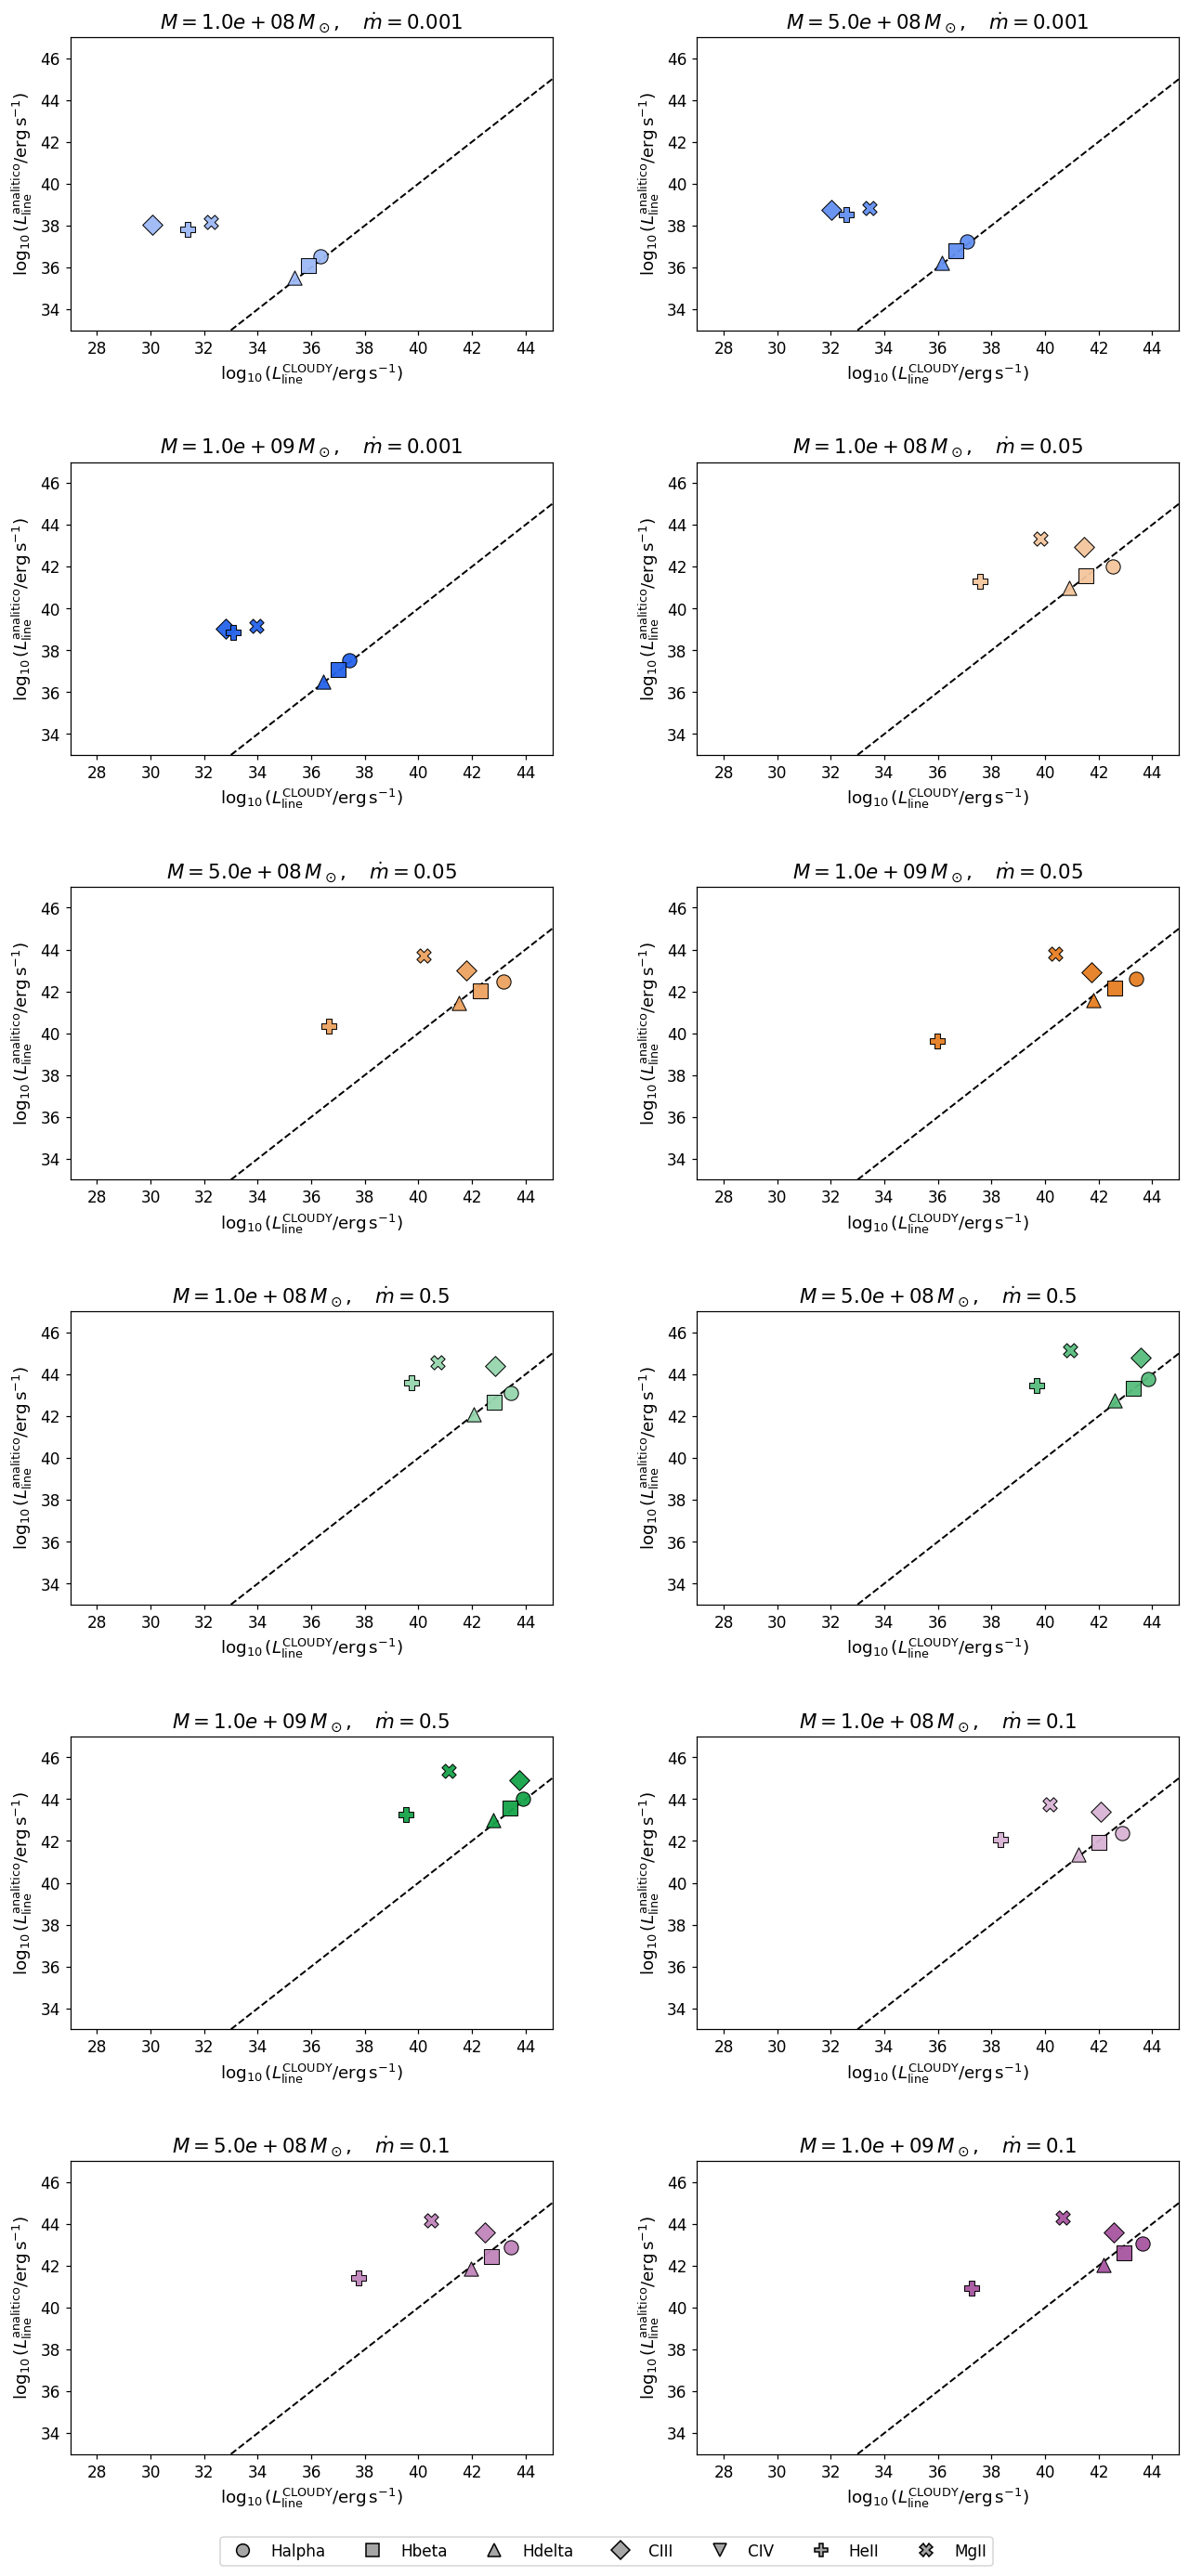

In [4]:

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ============================================================
# FIGURA CON 12 SOTTOPLOT: 6 RIGHE x 2 COLONNE
# ============================================================

fig, axes = plt.subplots(
    nrows=6,
    ncols=2,
    figsize=(14, 26),
    squeeze=False
)

# Limiti degli assi (puoi cambiarli o commentarli)
XMIN, XMAX = 27, 45
YMIN, YMAX = 33, 47

# Ordine: ogni riga della figura ha lo stesso mdot per due masse
combinations = [
    (mdot, mass)
    for mdot in MDOTS
    for mass in MASSES
]

for ax, (mdot, mass) in zip(axes.flat, combinations):

    # Seleziona tutti i punti della combinazione massa-mdot
    selected = comparison.loc[
        np.isclose(comparison["mdot"], mdot, rtol=1e-9)
        & np.isclose(comparison["massa"], mass, rtol=1e-9)
    ]

    # Stesso colore del grafico totale
    color = blend_with_white(
        BASE_COLORS[mdot],
        MASS_WEIGHTS[mass]
    )

    # Un simbolo per ciascuna delle 7 righe
    for line in LINES:

        rows = selected.loc[
            selected["elemento_ionizzato"] == line
        ]

        if rows.empty:
            continue

        ax.scatter(
            rows["logL_cloudy"].to_numpy(),
            rows["logL_analitico"].to_numpy(),
            marker=MARKERS[line],
            s=100,
            c=[color],
            edgecolors="black",
            linewidths=0.7,
            alpha=0.95,
            zorder=3
        )

    # Bisettrice y=x nello spazio dei logaritmi
    ax.axline(
        (0, 0),
        slope=1,
        color="black",
        linestyle="--",
        linewidth=1.3,
        zorder=1
    )

    # Titolo con massa e mdot della combinazione
    ax.set_title(
        rf"$M={mass:.1e}\,M_\odot,\quad \dot m={mdot:g}$",
        fontsize=14
    )

    ax.set_xlabel(
        r"$\log_{10}(L_{\rm line}^{\rm CLOUDY}/\mathrm{erg\,s^{-1}})$",
        fontsize=12
    )
    ax.set_ylabel(
        r"$\log_{10}(L_{\rm line}^{\rm analitico}/\mathrm{erg\,s^{-1}})$",
        fontsize=12
    )

    # Se non vuoi limiti fissi, commenta queste due righe
    ax.set_xlim(XMIN, XMAX)
    ax.set_ylim(YMIN, YMAX)



# ============================================================
# LEGENDA UNICA: SIMBOLI DELLE 7 RIGHE
# ============================================================

line_handles = [
    Line2D(
        [], [],
        marker=MARKERS[line],
        linestyle="None",
        markersize=9,
        markerfacecolor="0.65",
        markeredgecolor="black",
        label=line
    )
    for line in LINES
]

fig.legend(
    handles=line_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=7,
    fontsize=11,
    frameon=True
)



fig.subplots_adjust(
    top=0.965,
    bottom=0.055,
    hspace=0.45,
    wspace=0.30
)

# Salva la figura, se desideri
# fig.savefig(
#     "confronto_CLOUDY_analitico_12pannelli.png",
#     dpi=250,
#     bbox_inches="tight"
# )

plt.show()
